# Ahmad Bin Zia (1008)

# Actvity 2:

### SNM (Support Vector Machine)

In [2]:
!unzip -q "/content/archive (1).zip" -d /content/brain_mri

In [3]:
import os
for root, dirs, files in os.walk("/content/brain_mri"):
    if "yes" in dirs and "no" in dirs:
        print("DATA_DIR =", root)

DATA_DIR = /content/brain_mri
DATA_DIR = /content/brain_mri/brain_tumor_dataset


X shape: (253, 4096) | y shape: (253,)
Class counts -> no tumor: 98 | tumor: 155
Train: (202, 4096) | Test: (51, 4096)

Accuracy: 0.8431

Classification report:
              precision    recall  f1-score   support

    No Tumor       0.93      0.65      0.76        20
       Tumor       0.81      0.97      0.88        31

    accuracy                           0.84        51
   macro avg       0.87      0.81      0.82        51
weighted avg       0.86      0.84      0.84        51



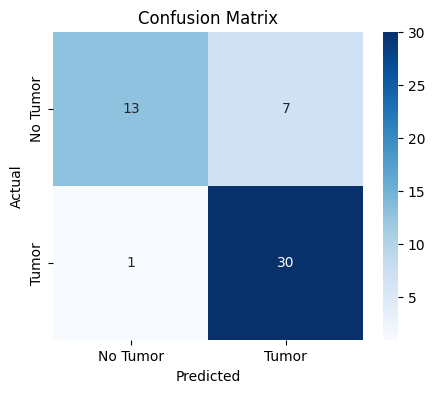

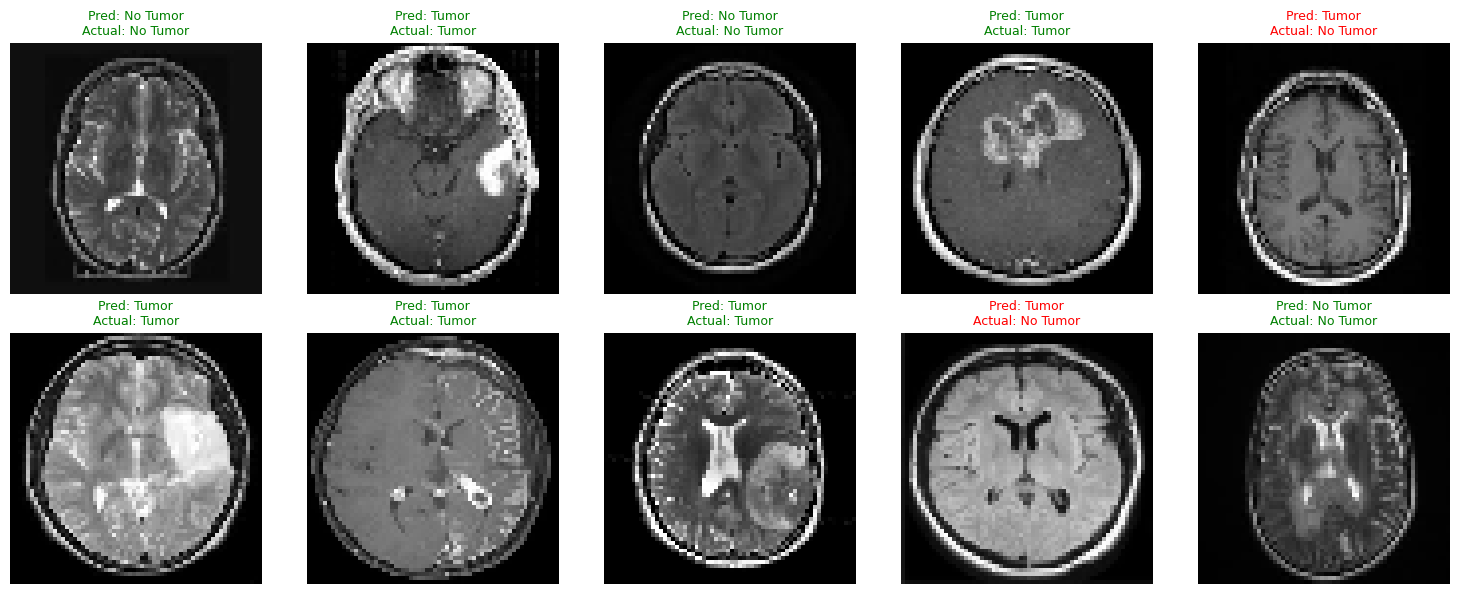

In [4]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Path
DATA_DIR = "/content/brain_mri/brain_tumor_dataset"
IMG_SIZE = 64
CLASSES = {"no": 0, "yes": 1}

# Load
X, y = [], []
for folder, label in CLASSES.items():
    folder_path = os.path.join(DATA_DIR, folder)
    for fname in os.listdir(folder_path):
        img = cv2.imread(os.path.join(folder_path, fname), cv2.IMREAD_GRAYSCALE)
        if img is None:
            continue
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        X.append(img.flatten())
        y.append(label)

X = np.array(X)
y = np.array(y)
print("X shape:", X.shape, "| y shape:", y.shape)
print("Class counts -> no tumor:", (y == 0).sum(), "| tumor:", (y == 1).sum())

# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

# Standard Scalar
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# SVM
svm = SVC(kernel="rbf", C=10, gamma="scale")
svm.fit(X_train_s, y_train)

# Evaluate
y_pred = svm.predict(X_test_s)
print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["No Tumor", "Tumor"]))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Tumor", "Tumor"], yticklabels=["No Tumor", "Tumor"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix")
plt.show()

# Test Images
names = {0: "No Tumor", 1: "Tumor"}
rng = np.random.RandomState(0)
idx = rng.choice(len(X_test), size=10, replace=False)

plt.figure(figsize=(15, 6))
for i, j in enumerate(idx):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[j].reshape(IMG_SIZE, IMG_SIZE), cmap="gray")
    correct = y_pred[j] == y_test[j]
    plt.title(f"Pred: {names[y_pred[j]]}\nActual: {names[y_test[j]]}",
              color="green" if correct else "red", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

# Activity 3:

### K Mean

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
5           6  Female   22                  17                      76
6           7  Female   35                  18                       6
7           8  Female   23                  18                      94
8           9    Male   64                  19                       3
9          10  Female   30                  19                      72

Shape: (200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  -

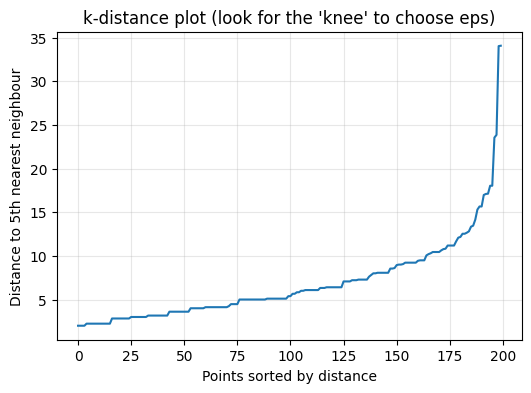

DBSCAN found 5 clusters and 87 noise points


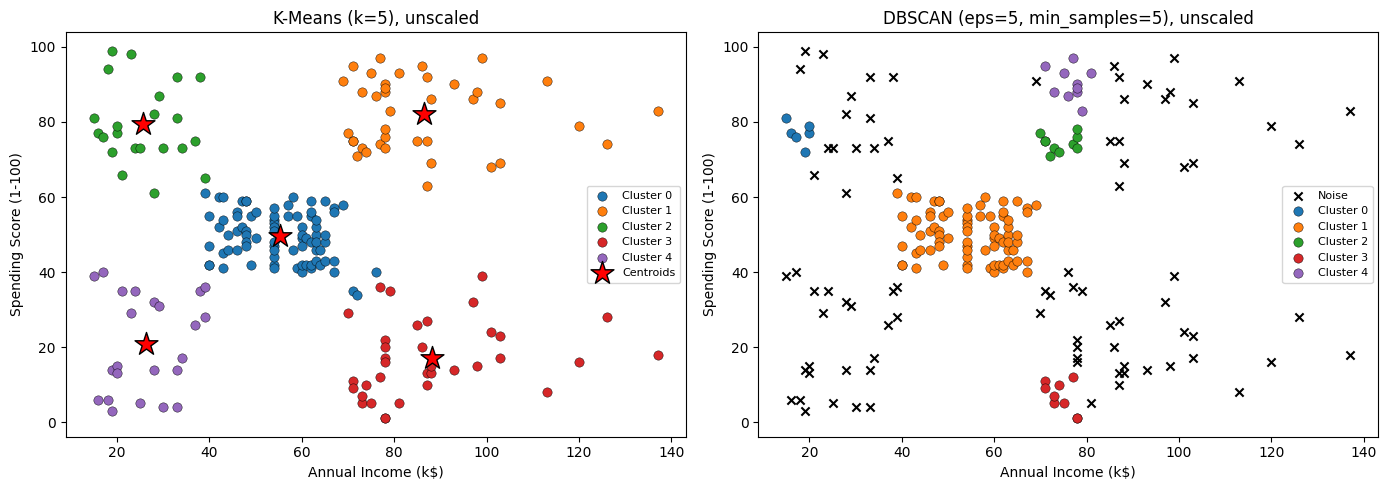

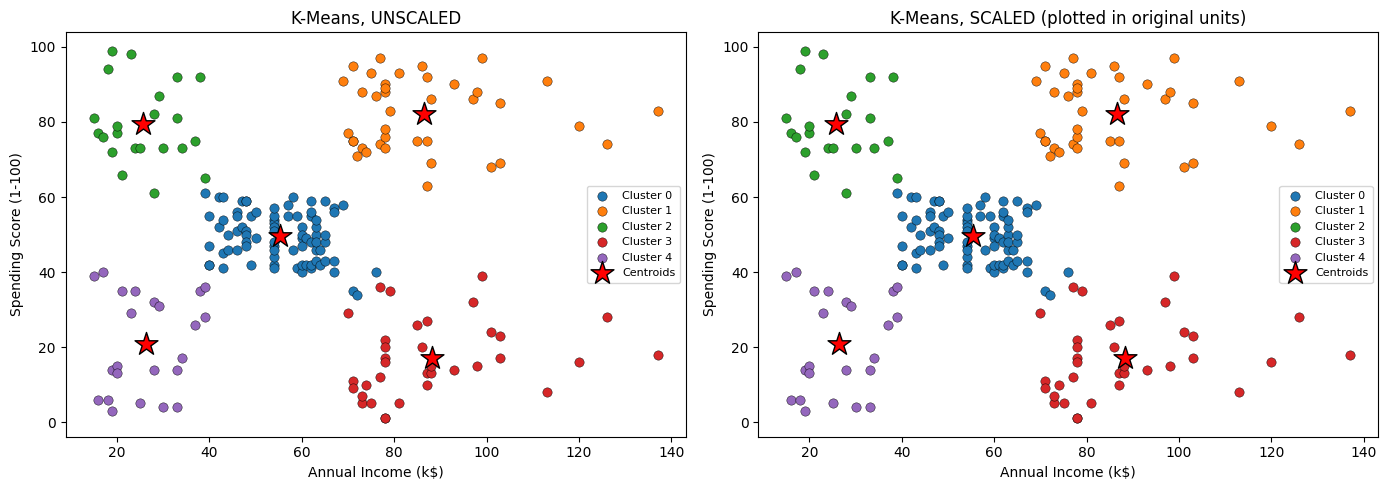

Feature std (unscaled): [26.2  25.76]

Adjusted Rand Index (unscaled vs scaled): 1.000  (1.0 = identical grouping)

Crosstab (rows = unscaled labels, columns = scaled labels):
col_0   0   1   2   3   4
row_0                    
0      81   0   0   0   0
1       0  39   0   0   0
2       0   0  22   0   0
3       0   0   0  35   0
4       0   0   0   0  23

Silhouette (measured in the scaled space):
  unscaled-run labels: 0.555
  scaled-run labels  : 0.555


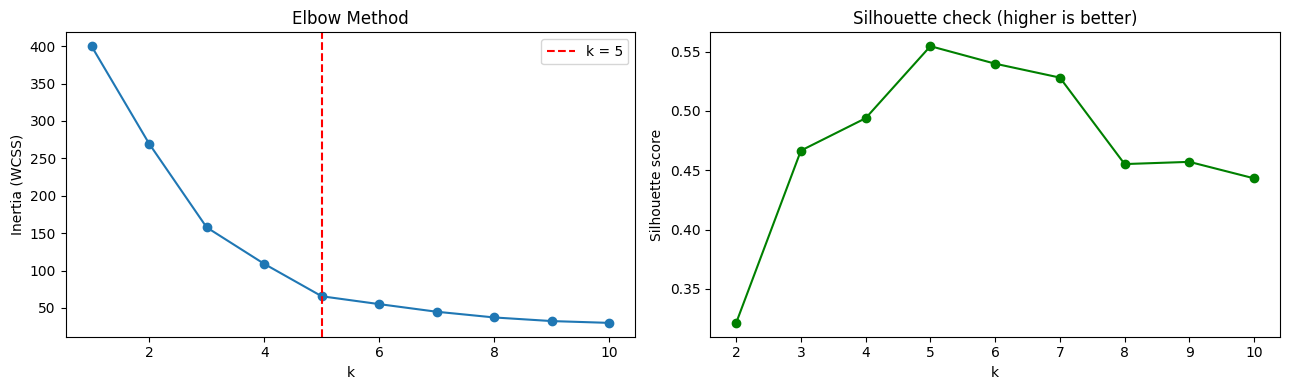

k= 1  inertia=  400.00  silhouette=nan
k= 2  inertia=  269.69  silhouette=0.321
k= 3  inertia=  157.70  silhouette=0.467
k= 4  inertia=  108.92  silhouette=0.494
k= 5  inertia=   65.57  silhouette=0.555
k= 6  inertia=   55.06  silhouette=0.540
k= 7  inertia=   44.86  silhouette=0.528
k= 8  inertia=   37.23  silhouette=0.455
k= 9  inertia=   32.39  silhouette=0.457
k=10  inertia=   29.98  silhouette=0.443
         Customers  Avg_Age  Avg_Income  Avg_Spending  \
Cluster                                                 
0               81     42.7        55.3          49.5   
1               39     32.7        86.5          82.1   
2               22     25.3        25.7          79.4   
3               35     41.1        88.2          17.1   
4               23     45.2        26.3          20.9   

                                       Segment  
Cluster                                         
0                            Average customers  
1        Target customers (rich, big spenders

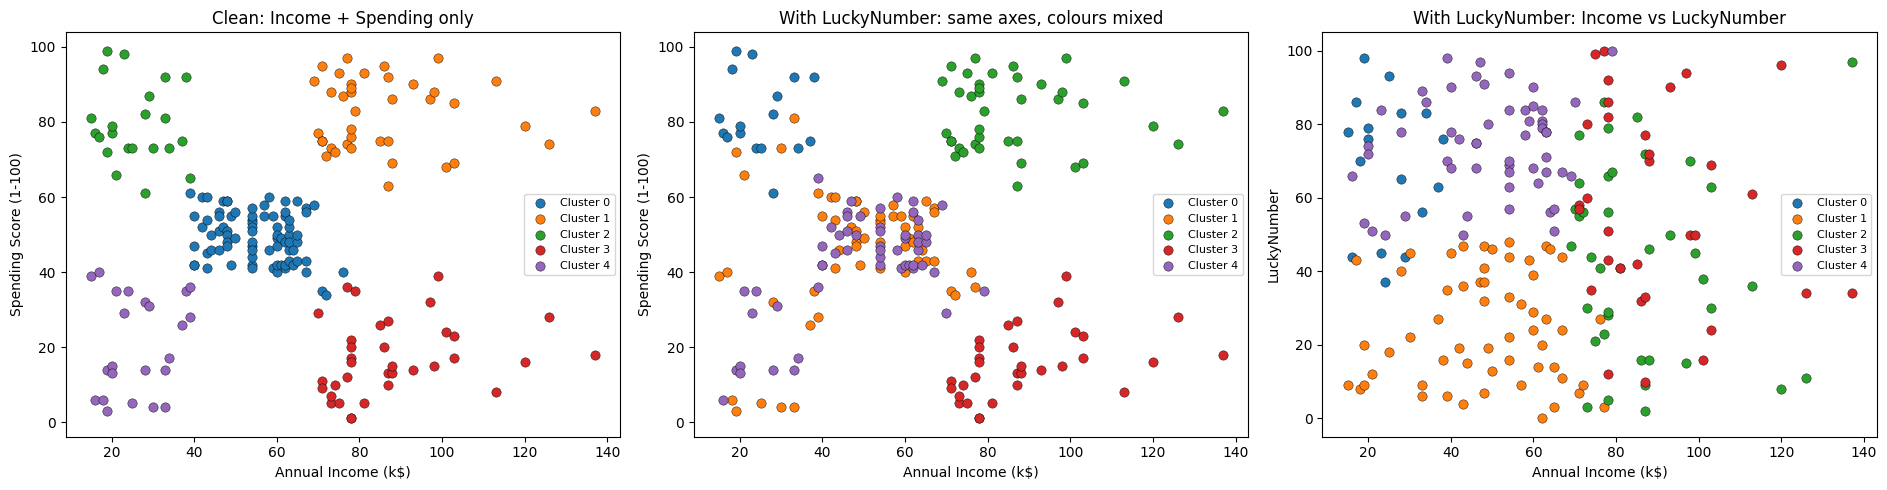

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Load Data
df = pd.read_csv("Mall_Customers (1).csv")

print(df.head(10))
print("\nShape:", df.shape)
df.info()
print("\nMissing values:\n", df.isnull().sum())
print("\n", df.describe().round(2))

INCOME = "Annual Income (k$)"          # change if your column is named differently
SPEND = "Spending Score (1-100)"

X = df[[INCOME, SPEND]].values          # the two features we cluster on


def plot_clusters(ax, data, labels, title, centers=None):
    """Scatter plot coloured by cluster. DBSCAN noise (-1) is shown as black x."""
    for lab in sorted(set(labels)):
        mask = labels == lab
        if lab == -1:
            ax.scatter(data[mask, 0], data[mask, 1], c="black", marker="x",
                       s=35, label="Noise")
        else:
            ax.scatter(data[mask, 0], data[mask, 1], color=plt.cm.tab10(lab % 10),
                       s=45, edgecolor="k", linewidth=0.3, label=f"Cluster {lab}")
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], c="red", marker="*", s=300,
                   edgecolor="k", label="Centroids")
    ax.set_xlabel("Annual Income (k$)")
    ax.set_ylabel("Spending Score (1-100)")
    ax.set_title(title)
    ax.legend(fontsize=8)


# K Mean and DBSCAN
km = KMeans(n_clusters=5, n_init=10, random_state=42)
labels_km = km.fit_predict(X)

min_samples = 5
nn = NearestNeighbors(n_neighbors=min_samples).fit(X)
distances, _ = nn.kneighbors(X)
k_dist = np.sort(distances[:, -1])

plt.figure(figsize=(6, 4))
plt.plot(k_dist)
plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to {min_samples}th nearest neighbour")
plt.title("k-distance plot (look for the 'knee' to choose eps)")
plt.grid(alpha=0.3)
plt.show()

# DBSCAN
db = DBSCAN(eps=5, min_samples=min_samples)
labels_db = db.fit_predict(X)

n_db_clusters = len(set(labels_db)) - (1 if -1 in labels_db else 0)
print(f"DBSCAN found {n_db_clusters} clusters and {(labels_db == -1).sum()} noise points")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_clusters(axes[0], X, labels_km, "K-Means (k=5), unscaled", km.cluster_centers_)
plot_clusters(axes[1], X, labels_db, "DBSCAN (eps=5, min_samples=5), unscaled")
plt.tight_layout()
plt.show()

# Standard Scalar
scaler = StandardScaler()
Xs = scaler.fit_transform(X)

km_s = KMeans(n_clusters=5, n_init=10, random_state=42)
labels_km_s = km_s.fit_predict(Xs)

centers_s_orig = scaler.inverse_transform(km_s.cluster_centers_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_clusters(axes[0], X, labels_km, "K-Means, UNSCALED", km.cluster_centers_)
plot_clusters(axes[1], X, labels_km_s, "K-Means, SCALED (plotted in original units)",
              centers_s_orig)
plt.tight_layout()
plt.show()

# Comparison
print("Feature std (unscaled):", X.std(axis=0).round(2))

ari = adjusted_rand_score(labels_km, labels_km_s)
print(f"\nAdjusted Rand Index (unscaled vs scaled): {ari:.3f}  (1.0 = identical grouping)")

print("\nCrosstab (rows = unscaled labels, columns = scaled labels):")
print(pd.crosstab(labels_km, labels_km_s))

print("\nSilhouette (measured in the scaled space):")
print("  unscaled-run labels:", round(silhouette_score(Xs, labels_km), 3))
print("  scaled-run labels  :", round(silhouette_score(Xs, labels_km_s), 3))

# Elbow Method
ks = range(1, 11)
inertias, sils = [], []
for k in ks:
    m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    inertias.append(m.inertia_)
    sils.append(silhouette_score(Xs, m.labels_) if k > 1 else np.nan)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(ks, inertias, "o-")
axes[0].axvline(5, color="red", linestyle="--", label="k = 5")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia (WCSS)")
axes[0].set_title("Elbow Method"); axes[0].legend()

axes[1].plot(ks, sils, "o-", color="green")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette check (higher is better)")
plt.tight_layout()
plt.show()

for k, i, s in zip(ks, inertias, sils):
    print(f"k={k:2d}  inertia={i:8.2f}  silhouette={s:.3f}")

# Interpretation
df["Cluster"] = labels_km_s

profile = df.groupby("Cluster").agg(
    Customers=("Cluster", "size"),
    Avg_Age=("Age", "mean"),
    Avg_Income=(INCOME, "mean"),
    Avg_Spending=(SPEND, "mean"),
).round(1)

z = km_s.cluster_centers_            # columns: [income_z, spending_z]


def level(v):
    return "High" if v > 0.5 else ("Low" if v < -0.5 else "Mid")


names = {
    ("High", "High"): "Target customers (rich, big spenders)",
    ("High", "Low"):  "Careful / frugal rich",
    ("Low", "High"):  "Impulsive low-income spenders",
    ("Low", "Low"):   "Budget-conscious customers",
    ("Mid", "Mid"):   "Average customers",
}
profile["Segment"] = [
    names.get((level(inc), level(sp)), f"{level(inc)} income / {level(sp)} spending")
    for inc, sp in z
]
print(profile)

# Fake Feature
rng = np.random.default_rng(42)
df["LuckyNumber"] = rng.integers(0, 101, size=len(df))

X3 = df[[INCOME, SPEND, "LuckyNumber"]].values
X3s = StandardScaler().fit_transform(X3)

km3 = KMeans(n_clusters=5, n_init=10, random_state=42)
labels3 = km3.fit_predict(X3s)

print("\n--- Effect of LuckyNumber ---")
print("ARI vs clean clustering:", round(adjusted_rand_score(labels_km_s, labels3), 3))
print("Silhouette on the 2 REAL features -> clean labels:",
      round(silhouette_score(Xs, labels_km_s), 3),
      "| lucky labels:", round(silhouette_score(Xs, labels3), 3))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
plot_clusters(axes[0], X, labels_km_s, "Clean: Income + Spending only")
plot_clusters(axes[1], X, labels3, "With LuckyNumber: same axes, colours mixed")
plot_clusters(axes[2], df[[INCOME, "LuckyNumber"]].values, labels3,
              "With LuckyNumber: Income vs LuckyNumber")
axes[2].set_ylabel("LuckyNumber")
plt.tight_layout()
plt.show()